# Laboration 2

## Excercise 1

In [1]:
from typing import List, Optional
import gymnasium as gym
import pygame
import numpy as np

from collections import namedtuple, deque
from pygame.colordict import THECOLORS as CM

Text = namedtuple("Text", ("message", "position", "color"))


class LunarGame:
    WIDTH: int = 600
    HEIGHT: int = 400
    FPS: int = 30
    CONTROL_MSG: Text = Text("Controls: LEFT, UP, RIGHT", (20, 20), CM["cadetblue"])
    START_MSG: Text = Text("Press 'R' to start.", (20, 20), CM["yellow"])
    LINDQVIST: float = 37.84

    def __init__(self):
        pygame.init()
        pygame.display.set_caption("Lunar Lander Control")
        self.screen = pygame.display.set_mode((LunarGame.WIDTH, LunarGame.HEIGHT))
        self.clock = pygame.time.Clock()
        self.ten_latest = deque(maxlen=10)
        self.env = gym.make("LunarLander-v3", render_mode="rgb_array")
        self.env.reset()

    def run(self):
        q = self._menu([LunarGame.START_MSG])
        while not q:
            if (g := self._episode_loop()) is None:
                break
            q = self._menu(
                [
                    LunarGame.START_MSG,
                ]
                + self._gen_menu_stats(g)
            )

    def _display_text(self, text: Text):
        font = pygame.font.SysFont("Arial", 18)
        text_surface = font.render(text.message, True, text.color)
        self.screen.blit(text_surface, text.position)

    def _render_frame(self):
        img = self.env.render()
        img = np.rot90(img)
        img_surface = pygame.surfarray.make_surface(img)
        self.screen.blit(img_surface, (0, 0))
        self._display_text(LunarGame.CONTROL_MSG)
        pygame.display.flip()
        self.clock.tick(LunarGame.FPS)

    def _read_action() -> int:
        keys = pygame.key.get_pressed()
        if keys[pygame.K_LEFT]:
            action = 1  # LEFT ENGINE
        elif keys[pygame.K_UP]:
            action = 2  # MAIN ENGINE
        elif keys[pygame.K_RIGHT]:
            action = 3  # RIGHT ENGINE
        else:
            action = 0
        return action

    def _menu(self, textlst: List[Text]) -> bool:
        self.screen.fill(CM["black"])
        r_pressed = False
        for text in textlst:
            self._display_text(text)
        pygame.display.flip()
        while not r_pressed:
            if self._check_quit():
                return True
            self.clock.tick(LunarGame.FPS)
            r_pressed = pygame.key.get_pressed()[pygame.K_r]
        return False

    def _check_quit(self) -> bool:
        for event in pygame.event.get():
            if event.type == pygame.QUIT:
                pygame.quit()
                self.env.close()
                return True
        return False

    def _episode_loop(self) -> Optional[float]:
        episode_return = 0
        while True:
            if self._check_quit():
                return None
            action = LunarGame._read_action()
            _, reward, terminated, _, _ = self.env.step(action)
            episode_return += reward
            self._render_frame()
            if terminated:
                self.env.reset()
                break
        return episode_return

    def _gen_menu_stats(self, g: float) -> List[Text]:
        self.ten_latest.append(g)
        num_samples = len(self.ten_latest)
        ma5 = np.mean(self.ten_latest)
        ma5str = "MA10: " + (
            f"{ma5:.2f}"
            if num_samples == 10
            else f"N/A (only {num_samples} sample"
            + ("s" if num_samples > 1 else "")
            + ")"
        )
        ma5color = CM["red"] if ma5 < LunarGame.LINDQVIST else CM["green"]
        hist1 = f"Latest: {np.round(list(self.ten_latest)[:5],2)}"
        hist2 = (
            " " * 17 + f"{np.round(list(self.ten_latest)[5:],2)}"
            if num_samples > 5
            else ""
        )
        return [
            Text(s, (20, 60 + i * 40), c)
            for i, (s, c) in enumerate(
                [
                    (f"Last return: {g:.2f}", CM["white"]),
                    (ma5str, ma5color),
                    (hist1, CM["white"]),
                    (hist2, CM["white"]),
                ]
            )
        ]

# game = LunarGame()
# game.run()
# print(
#     f"Game exited.\nLatest: {np.round(list(game.ten_latest), 2)}\nAvg: {np.mean(game.ten_latest):.2f}"
# )

## Excercise 2

In [2]:
import random
from multipledispatch import dispatch

Transition = namedtuple(
    "Transition", ("state", "action", "reward", "next_state", "terminated")
)
Batch = namedtuple(
    "Batch", ("states", "actions", "rewards", "next_states", "terminateds")
)


class ReplayMemory:
    """Replay buffer storing transitions and sampling mini-batches."""

    def __init__(self, capacity: int, batch_size: int):
        if capacity <= 0 or batch_size <= 0:
            raise ValueError("capacity and batch_size must be positive")
        self.batch_size = batch_size
        self.memory = deque(maxlen=capacity)

    def __len__(self):
        return len(self.memory)

    @dispatch(Transition)
    def add(self, transition: Transition):
        self.memory.append(transition)

    @dispatch(object, object, object, object, object)
    def add(self, state, action, reward, next_state, terminated):
        # Store independent copies so later changes to an observation cannot
        # modify transitions already in the replay buffer.
        self.memory.append(
            Transition(
                np.asarray(state, dtype=np.float32).copy(),
                int(action),
                float(reward),
                np.asarray(next_state, dtype=np.float32).copy(),
                bool(terminated),
            )
        )

    def sample(self) -> Batch:
        if len(self.memory) < self.batch_size:
            raise ValueError(
                f"Need at least {self.batch_size} transitions, "
                f"but buffer contains {len(self.memory)}."
            )

        transitions = random.sample(self.memory, self.batch_size)
        states, actions, rewards, next_states, terminateds = zip(*transitions)

        if isinstance(actions[0], int):
            actions = torch.as_tensor(actions, dtype=torch.int64)
        else:
            actions = torch.stack(actions)
        return Batch(
            states=torch.as_tensor(np.asarray(states), dtype=torch.float32),
            actions=actions,
            rewards=torch.as_tensor(rewards, dtype=torch.float32),
            next_states=torch.as_tensor(np.asarray(next_states), dtype=torch.float32),
            terminateds=torch.as_tensor(terminateds, dtype=torch.float32),
        )

In [3]:
import torch
from torch import nn

class Net(nn.Module):
    def __init__(self, hidden, use_gradient=True):
        super().__init__()
        if len(hidden) < 2:
            raise ValueError("hidden must contain input and output dimensions")
        self.hidden = tuple(hidden)
        self.use_gradient = use_gradient

        # Input for LunarLander is 8-dimensional, output is 4-dimensional (4 actions)
        self.layers = nn.ModuleList(
            [nn.Linear(hidden[i - 1], hidden[i]) for i in range(1, len(hidden))]
        )

        if not self.use_gradient:
            self._freeze_parameters()

    def _freeze_parameters(self):
        for param in self.parameters():
            param.requires_grad = False

    def forward(self, x):
        x = torch.as_tensor(x, dtype=torch.float32)
        if x.shape[-1] != self.hidden[0]:
            raise ValueError(
                f"Expected input dimension {self.hidden[0]}, got {x.shape[-1]}"
            )
        for i, layer in enumerate(self.layers):
            x = layer(x)
            if i < len(self.layers) - 1:
                x = torch.relu(x)
        return x


class Agent:
    def __init__(self, *hidden, gamma, lr, lamda):
        self.Qnet = Net(hidden, use_gradient=True)
        self.Tnet = Net(hidden, use_gradient=False)
        self.Tnet.load_state_dict(self.Qnet.state_dict())
        self.gamma = float(gamma)
        self.lamda = float(lamda)
        self.optimizer = torch.optim.Adam(self.Qnet.parameters(), lr=lr)
        self.buffer = ReplayMemory(capacity=50000, batch_size=32)

    def save(self, path):
        torch.save(self.Qnet.state_dict(), path)

    def load(self, path):
        self.Qnet.load_state_dict(torch.load(path, weights_only=True))
        self.Tnet.load_state_dict(torch.load(path, weights_only=True))

    @torch.no_grad()
    def greedy_action(self, state):
        state = torch.as_tensor(state, dtype=torch.float32)
        if state.ndim == 1:
            state = state.unsqueeze(0)
        return int(self.Qnet(state).argmax(dim=1).item())

    @torch.no_grad()
    def epsilon_greedy_action(self, state, epsilon, n_actions=4):
        if random.random() < epsilon:
            return random.randrange(n_actions)
        return self.greedy_action(state)

    def update_target_network(self):
        """Softly update target parameters toward the online network."""
        with torch.no_grad():
            for target_param, online_param in zip(self.Tnet.parameters(), self.Qnet.parameters()):
                target_param.copy_((1 - self.lamda) * target_param + self.lamda * online_param)

    def add_transition(self, state, action, reward, next_state, terminated):
        self.buffer.add(state, action, reward, next_state, terminated)

    def batch_update(self) -> float:
        """Q-learning update using a mini-batch sampled from replay memory."""
        batch = self.buffer.sample()
        states = torch.as_tensor(batch.states, dtype=torch.float32)
        actions = torch.as_tensor(batch.actions, dtype=torch.int64).reshape(-1)
        rewards = torch.as_tensor(batch.rewards, dtype=torch.float32).reshape(-1)
        next_states = torch.as_tensor(batch.next_states, dtype=torch.float32)
        terminateds = torch.as_tensor(
            batch.terminateds, dtype=torch.float32
        ).reshape(-1)

        q_sa = self.Qnet(states).gather(1, actions.unsqueeze(1)).squeeze(1)
        # The bootstrap target must not be part of the gradient graph.
        with torch.no_grad():
            next_q_max = self.Tnet(next_states).max(dim=1).values
            targets = rewards + self.gamma * (1.0 - terminateds) * next_q_max

        loss = nn.functional.mse_loss(q_sa, targets)
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        return float(loss.item())


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import tqdm


MAX_STEP_LENGTH = 2000
EPISODES = 500
EXPERIMENTS = 3

HIDDEN = [8, 256, 256, 256, 4]
GAMMA = 0.99
LR = 1e-4
TAU = 0.05 ** (1 / 100)
LAMDA = 0.01

SAVE_DIR = "models/"


def _create_agent(hidden, **params) -> Agent:
    return Agent(*hidden, **params)

def DQN_training(
    env: gym.Env,
    num_episodes: int,
    epsilon_start: float = 1.0,
    epsilon_end: float = 0.05,
    epsilon_decay: float = TAU,
) -> tuple[Agent, list[float]]:
    """Train the agent using Deep Q-Learning."""
    per_episode_reward = []
    epsilon = epsilon_start
    agent = _create_agent(hidden=HIDDEN, gamma=GAMMA, lr=LR, lamda=LAMDA)
    for episode in tqdm.tqdm(range(num_episodes), desc="Training"):
        state, _ = env.reset()
        total_reward = 0
        done = False

        while not done:
            action = agent.epsilon_greedy_action(state, epsilon)
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            agent.add_transition(state, action, reward, next_state, terminated)
            state = next_state
            total_reward += reward

            if len(agent.buffer) >= agent.buffer.batch_size:
                loss = agent.batch_update()
                agent.update_target_network()

        epsilon = max(epsilon_end, epsilon * epsilon_decay)
        per_episode_reward.append(total_reward)
    return agent, per_episode_reward

def compute_MA10(returns: list[float]) -> list[float]:
    """Compute the moving average of the last 10 returns."""
    ma10 = []
    for i in range(len(returns)):
        if i < 9:
            ma10.append(np.mean(returns[:i + 1]))
        else:
            ma10.append(np.mean(returns[i - 9:i + 1]))
    return ma10

def plot_averaged_experiments(plot_df: pd.DataFrame):
    """Plot the mean MA10 reward across experiments."""

    plt.figure(figsize=(12, 6))
    sns.lineplot(
        data=plot_df,
        x="Episode",
        y="Value",
        estimator="mean",
        errorbar="sd",
        err_style="band",
    )
    plt.title("Average MA10 reward across experiments")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


Starting experiment 1/3


Training: 100%|██████████| 500/500 [17:42<00:00,  2.13s/it] 


Experiment 1 completed. Model saved to models/lunarlander_dqn_exp1.pth.
Starting experiment 2/3


Training: 100%|██████████| 500/500 [23:45<00:00,  2.85s/it]  


Experiment 2 completed. Model saved to models/lunarlander_dqn_exp2.pth.
Starting experiment 3/3


Training: 100%|██████████| 500/500 [15:27<00:00,  1.85s/it]


Experiment 3 completed. Model saved to models/lunarlander_dqn_exp3.pth.


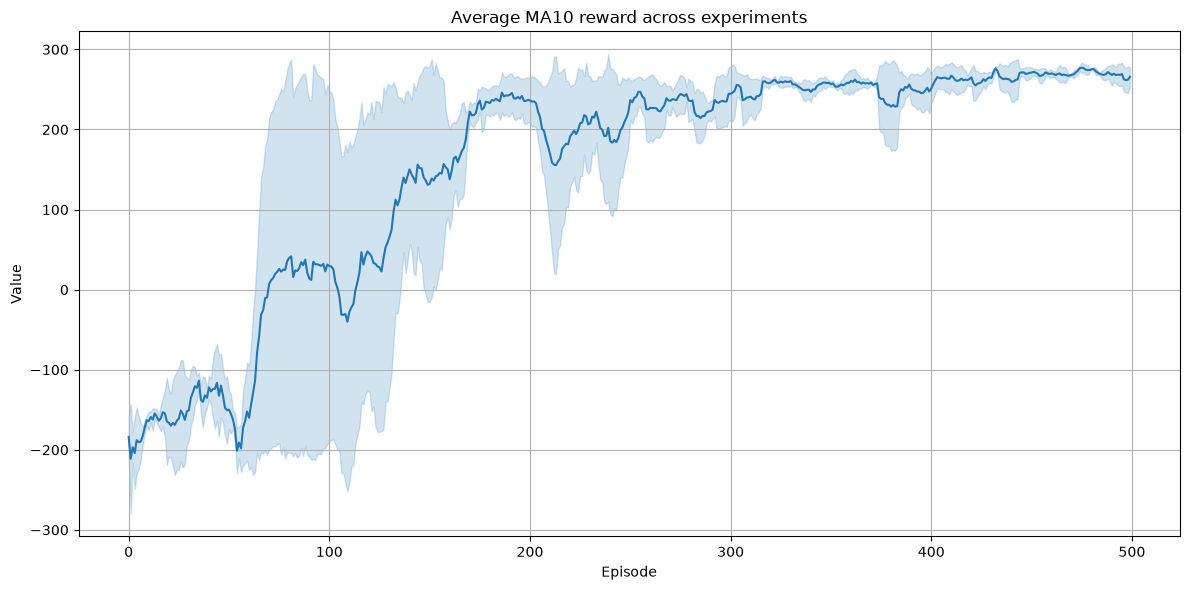

In [5]:
env = gym.make("LunarLander-v3", max_episode_steps=MAX_STEP_LENGTH)
experiment_rows = []

for exp in range(EXPERIMENTS):
    print(f"Starting experiment {exp + 1}/{EXPERIMENTS}")
    agent, per_episode_reward = DQN_training(env, EPISODES)
    ma10 = compute_MA10(per_episode_reward)

    experiment_rows.extend(
        {
            "Experiment": exp + 1,
            "Episode": episode,
            "Metric": "MA10 reward",
            "Value": float(value),
        }
        for episode, value in enumerate(ma10)
    )

    SAVE_PATH = SAVE_DIR + f"lunarlander_dqn_exp{exp + 1}.pth"
    agent.save(SAVE_PATH)
    print(f"Experiment {exp + 1} completed. Model saved to {SAVE_PATH}.")

experiment_data = pd.DataFrame(experiment_rows)

plot_averaged_experiments(experiment_data)

env.close()

In [5]:
TEST_EPISODES = 10
ONLY_BEST = False

agents = []

if ONLY_BEST:
    agent = _create_agent(hidden=HIDDEN, gamma=GAMMA, lr=LR, lamda=LAMDA)
    agent.load(SAVE_DIR + f"best_lunarlander_dqn.pth")
    agents.append(agent)
else:
    for i in range(EXPERIMENTS):
        agent = _create_agent(hidden=HIDDEN, gamma=GAMMA, lr=LR, lamda=LAMDA)
        agent.load(SAVE_DIR + f"lunarlander_dqn_exp{i+1}.pth")
        agents.append(agent)

env = gym.make("LunarLander-v3", render_mode="human", max_episode_steps=MAX_STEP_LENGTH)

episode_rewards = []

for i, agent in enumerate(agents):
    for episode in range(TEST_EPISODES):
        state, _ = env.reset()
        total_reward = 0
        done = False

        while not done:
            action = agent.greedy_action(state)
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            state = next_state
            total_reward += reward

        episode_rewards.append(total_reward)

    ma10_test = compute_MA10(episode_rewards)
    print(f"Test results over {TEST_EPISODES} episodes with agent {i+1}: {ma10_test[-1]:.2f}")
    episode_rewards = []

env.close()

Test results over 10 episodes with agent 1: 228.91
Test results over 10 episodes with agent 2: 255.35
Test results over 10 episodes with agent 3: 279.02


## Excercise 3

In [6]:
class Qfunction(nn.Module):
    def __init__(self, hidden_dim=128):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(10, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, states, actions):
        x = torch.cat([states, actions], dim=1)
        return self.net(x)


class GaussianPolicy(nn.Module):
    def __init__(self, hidden_dim=128):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(8, hidden_dim),
            nn.ReLU()
        )

        self.mean_net = nn.Linear(hidden_dim, 2)

        self.std_net = nn.Linear(hidden_dim, 2)

    def forward(self, states):

        features = self.encoder(states)
        mean = self.mean_net(features)
        std = torch.exp(torch.clamp(self.std_net(features), -20, 2))

        gaussian = torch.distributions.Normal(mean, std)

        u = gaussian.rsample()
        a = torch.tanh(u)

        inv_det_jacobian = torch.sum(
            2 * (np.log(2) - u - nn.functional.softplus(-2 * u)), dim=-1
        )
        log_pi_u = gaussian.log_prob(u).sum(axis=-1)
        log_prob_a = log_pi_u - inv_det_jacobian
        
        return a, (log_prob_a, log_pi_u)


class SacAgent(nn.Module):
    def __init__(self, hidden_dim=128, gamma=0.99, lr=3e-4):
        super().__init__()

        self.policy = GaussianPolicy(hidden_dim)

        self.Q1 = Qfunction(hidden_dim)
        self.Q2 = Qfunction(hidden_dim)

        self.target_Q1 = Qfunction(hidden_dim)
        self.target_Q2 = Qfunction(hidden_dim)

        self.clone()

        self.gamma = gamma

        self.policy_optimizer = torch.optim.Adam(
            self.policy.parameters(), lr=lr)
        self.Q1_optimizer = torch.optim.Adam(
            self.Q1.parameters(), lr=lr)
        self.Q2_optimizer = torch.optim.Adam(
            self.Q2.parameters(), lr=lr)

        self.memory = ReplayMemory(capacity=50000, batch_size=128)

    @torch.no_grad()
    def clone(self):
        self.target_Q1.load_state_dict(self.Q1.state_dict())
        self.target_Q2.load_state_dict(self.Q2.state_dict())

    @torch.no_grad()
    def soft_update(self, lamda=0.005):
        for target_param, param in zip(self.target_Q1.parameters(), self.Q1.parameters()):
            target_param.copy_(lamda * param + (1 - lamda) * target_param)

        for target_param, param in zip(self.target_Q2.parameters(), self.Q2.parameters()):
            target_param.copy_(lamda * param + (1 - lamda) * target_param)

    @torch.no_grad()
    def sample_action(self, state) -> tuple[float, float, float]:
        state = torch.as_tensor(state, dtype=torch.float32).unsqueeze(0)
        action, _ = self.policy(state)
        return action.squeeze(0).numpy()

    def update(self, batch=None, alpha=1.0):
        
        if batch is None:
            batch = self.memory.sample()
        
        states = batch.states
        actions = batch.actions
        rewards = batch.rewards
        next_states = batch.next_states
        terminateds = batch.terminateds

        # Update Q-functions
        with torch.no_grad():
            next_actions, (log_prob_next_actions, _) = self.policy(next_states)
            target_Q1_values = self.target_Q1(next_states, next_actions)
            target_Q2_values = self.target_Q2(next_states, next_actions)
            target_Q_values = torch.min(target_Q1_values, target_Q2_values) - alpha * log_prob_next_actions.unsqueeze(1)
            targets = rewards.unsqueeze(1) + self.gamma * (1 - terminateds.unsqueeze(1)) * target_Q_values

        Q1_values = self.Q1(states, actions)
        Q2_values = self.Q2(states, actions)

        Q1_loss = nn.functional.mse_loss(Q1_values, targets)
        Q2_loss = nn.functional.mse_loss(Q2_values, targets)

        self.Q1_optimizer.zero_grad()
        Q1_loss.backward()
        self.Q1_optimizer.step()

        self.Q2_optimizer.zero_grad()
        Q2_loss.backward()
        self.Q2_optimizer.step()

        # Update policy
        new_actions, (log_prob_new_actions, _) = self.policy(states)
        Q1_new_actions = self.Q1(states, new_actions)
        Q2_new_actions = self.Q2(states, new_actions)

        for p in self.Q1.parameters():
            p.requires_grad_(False)

        for p in self.Q2.parameters():
            p.requires_grad_(False)

        min_Q_new_actions = torch.min(Q1_new_actions, Q2_new_actions)

        policy_loss = (alpha * log_prob_new_actions.unsqueeze(1) - min_Q_new_actions).mean()

        self.policy_optimizer.zero_grad()
        policy_loss.backward()
        self.policy_optimizer.step()

        for p in self.Q1.parameters():
            p.requires_grad_(True)

        for p in self.Q2.parameters():
            p.requires_grad_(True)

        return Q1_loss, Q2_loss, policy_loss

    def save(self, path="sac_agent.pth"):
        torch.save({
            "policy": self.policy.state_dict(),
            "Q1": self.Q1.state_dict(),
            "Q2": self.Q2.state_dict(),
            "target_Q1": self.target_Q1.state_dict(),
            "target_Q2": self.target_Q2.state_dict(),

            "policy_optimizer": self.policy_optimizer.state_dict(),
            "Q1_optimizer": self.Q1_optimizer.state_dict(),
            "Q2_optimizer": self.Q2_optimizer.state_dict(),

            "gamma": self.gamma,
        }, path)


    def load(self, path="sac_agent.pth"):
        checkpoint = torch.load(path, weights_only=True)

        self.policy.load_state_dict(checkpoint["policy"])
        self.Q1.load_state_dict(checkpoint["Q1"])
        self.Q2.load_state_dict(checkpoint["Q2"])
        self.target_Q1.load_state_dict(checkpoint["target_Q1"])
        self.target_Q2.load_state_dict(checkpoint["target_Q2"])

        self.policy_optimizer.load_state_dict(checkpoint["policy_optimizer"])
        self.Q1_optimizer.load_state_dict(checkpoint["Q1_optimizer"])
        self.Q2_optimizer.load_state_dict(checkpoint["Q2_optimizer"])

        self.gamma = checkpoint["gamma"]

    @dispatch(Transition)
    def store(self, transition):
        self.memory.add(transition)

    @dispatch(object, object, object, object, object)
    def store(self, state, action, reward, next_state, terminated):
        self.memory.add(state, action, reward, next_state, terminated)

In [7]:
MAX_STEP_LENGTH = 2000
EPISODES = 500
EXPERIMENTS = 3

HIDDEN = 128
GAMMA = 0.99
LR = 1e-3
TAU = 0.1 ** (1 / 200)
LAMDA = 0.005

SAVE_DIR = "models/"

def _create_sac_agent(hidden, **params) -> SacAgent:
    return SacAgent(hidden, **params)

def SAC_training(
    env: gym.Env,
    human_env: gym.Env,
    human_freq: int,
    num_episodes: int,
    alpha = 1.0,
    alpha_min = 0.1,
    alpha_decay: float = TAU,
) -> tuple[Agent, list[float]]:
    """Train the SacAgent using Deep Q-Learning."""
    per_episode_reward = []
    Sac_agent = _create_sac_agent(hidden=HIDDEN, gamma=GAMMA, lr=LR)
    for episode in tqdm.tqdm(range(num_episodes), desc="Training"):
        state, _ = env.reset()
        total_reward = 0
        total_loss = []
        done = False

        while not done:
            action = Sac_agent.sample_action(state)
            next_state, reward, terminated, truncated, _ = env.step(action)
            action = torch.as_tensor(action)
            done = terminated or truncated
            transition = Transition(state, action, reward, next_state, terminated)
            Sac_agent.store(transition)
            state = next_state
            total_reward += reward

            if len(Sac_agent.memory) >= Sac_agent.memory.batch_size:
                Q1_loss, Q2_loss, policy_loss = Sac_agent.update(alpha=alpha)
                total_loss.append([Q1_loss.item(), Q2_loss.item(), policy_loss.item()])
                Sac_agent.soft_update(lamda=LAMDA)

        if human_env is not None and (episode % human_freq == 0 or episode == num_episodes - 1):
            human_state, _ = human_env.reset()
            human_done = False
            while not human_done:
                human_action = Sac_agent.sample_action(human_state)
                human_next_state, human_reward, human_terminated, human_truncated, _ = human_env.step(human_action)
                human_done = human_terminated or human_truncated
                human_state = human_next_state

        alpha = max(alpha_min, alpha * alpha_decay)
        per_episode_reward.append(total_reward)
    return Sac_agent, per_episode_reward, total_loss

def plot_sac_losses(per_episode_loss):
    loss_names = ["Q1 loss", "Q2 loss", "Policy loss"]
    episode_means = []

    for episode, losses in enumerate(per_episode_loss):
        values = np.asarray(losses, dtype=float)
        if values.size:
            episode_means.append((episode, values.reshape(-1, 3).mean(axis=0)))

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for index, (ax, name) in enumerate(zip(axes, loss_names)):
        data = pd.DataFrame(
            {
                "Episode": [episode for episode, _ in episode_means],
                "Loss": [means[index] for _, means in episode_means],
            }
        )
        sns.lineplot(data=data, x="Episode", y="Loss", ax=ax)
        ax.set_title(name)
        ax.grid(True)

    plt.tight_layout()
    plt.show()

Starting experiment 1/3


Training: 100%|██████████| 500/500 [1:44:35<00:00, 12.55s/it]  


Experiment 1 completed. Model saved to models/lunarlander_sac_exp1.pth.
Starting experiment 2/3


Training: 100%|██████████| 500/500 [1:11:40<00:00,  8.60s/it]


Experiment 2 completed. Model saved to models/lunarlander_sac_exp2.pth.
Starting experiment 3/3


Training: 100%|██████████| 500/500 [1:20:46<00:00,  9.69s/it]  


Experiment 3 completed. Model saved to models/lunarlander_sac_exp3.pth.


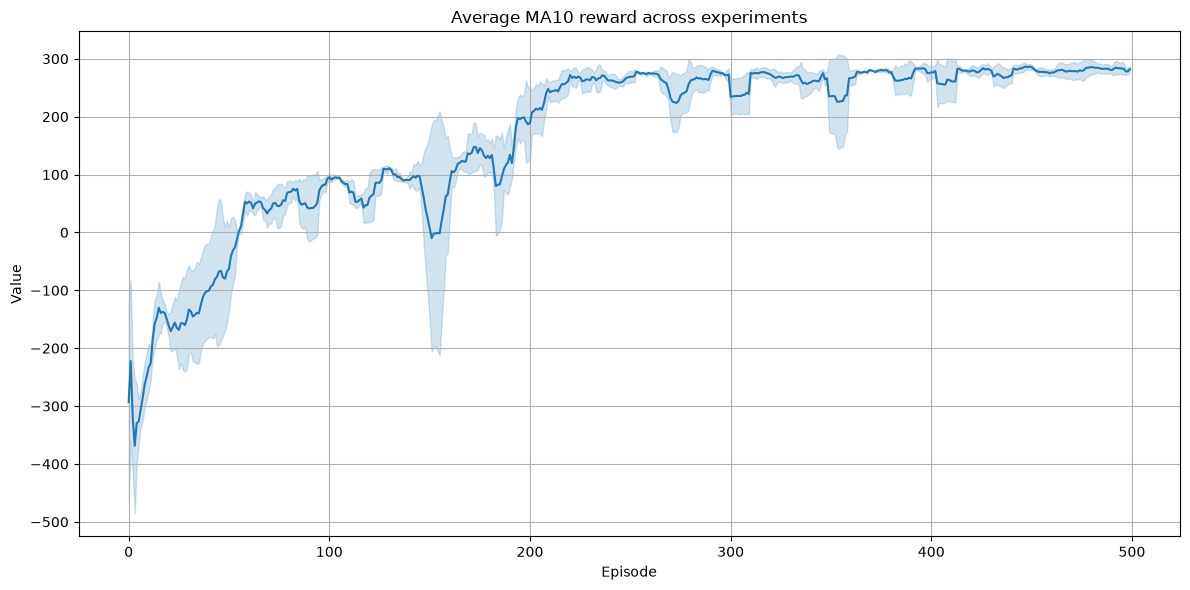

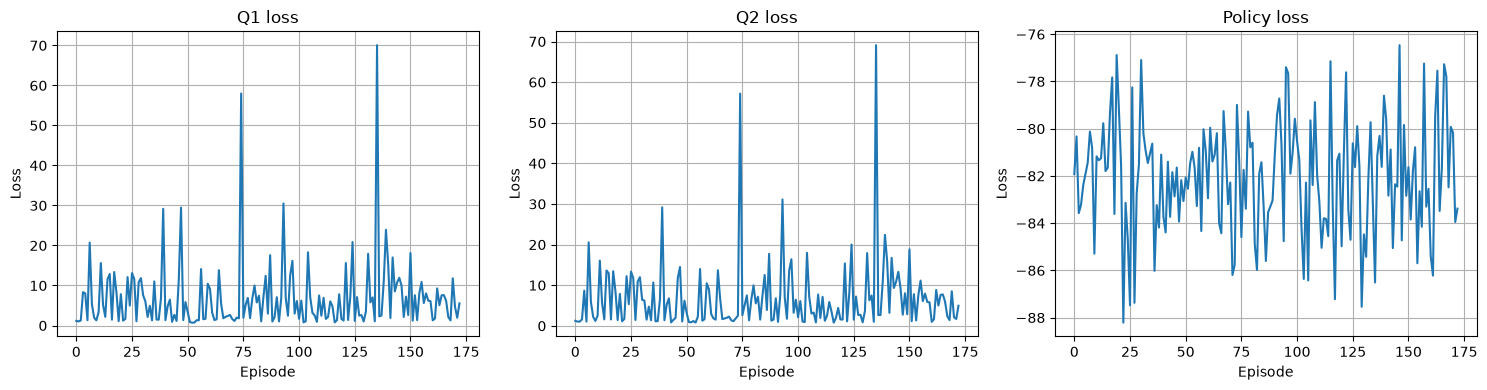

In [8]:
env = gym.make("LunarLander-v3", continuous=True, max_episode_steps=MAX_STEP_LENGTH)
human_env = gym.make("LunarLander-v3", continuous=True, render_mode="human", max_episode_steps=MAX_STEP_LENGTH)
experiment_rows = []
experiment_rows_loss = []

for exp in range(EXPERIMENTS):
    print(f"Starting experiment {exp + 1}/{EXPERIMENTS}")
    agent, per_episode_reward, per_episode_loss = SAC_training(env=env, human_env = None, human_freq=5, num_episodes=EPISODES)
    loss = pd.DataFrame(per_episode_loss, columns=["Q1_loss", "Q2_loss", "policy_loss"])
    ma10 = compute_MA10(per_episode_reward)

    experiment_rows.extend(
        {
            "Experiment": exp + 1,
            "Episode": episode,
            "Metric": "MA10 reward",
            "Value": float(value),
        }
        for episode, value in enumerate(ma10)
    )

    SAVE_PATH = SAVE_DIR + f"lunarlander_sac_exp{exp + 1}.pth"
    agent.save(SAVE_PATH)
    print(f"Experiment {exp + 1} completed. Model saved to {SAVE_PATH}.")

experiment_data = pd.DataFrame(experiment_rows)

plot_averaged_experiments(experiment_data)
plot_sac_losses(per_episode_loss)

env.close()
human_env.close()

In [9]:
TEST_EPISODES = 3
ONLY_BEST = False

agents = []

if ONLY_BEST:
    agent = _create_agent(hidden=HIDDEN, gamma=GAMMA, lr=LR)
    agent.load(SAVE_DIR + f"best_lunarlander_sac.pth")
    agents.append(agent)
else:
    for i in range(EXPERIMENTS):
        agent = _create_sac_agent(hidden=HIDDEN, gamma=GAMMA, lr=LR)
        agent.load(SAVE_DIR + f"lunarlander_sac_exp{i+1}.pth")
        agents.append(agent)

env = gym.make("LunarLander-v3", continuous=True, render_mode="human", max_episode_steps=MAX_STEP_LENGTH)

episode_rewards = []

for i, agent in enumerate(agents):
    for episode in range(TEST_EPISODES):
        state, _ = env.reset()
        total_reward = 0
        done = False

        while not done:
            action = agent.sample_action(state)
            next_state, reward, terminated, truncated, _ = env.step(action)
            action = torch.as_tensor(action)
            done = terminated or truncated
            transition = Transition(state, action, reward, next_state, terminated)
            agent.store(transition)
            state = next_state
            total_reward += reward

        episode_rewards.append(total_reward)

    ma10_test = compute_MA10(episode_rewards)
    print(f"Test results over {TEST_EPISODES} episodes with agent {i+1}: {ma10_test[-1]:.2f}")
    episode_rewards = []

env.close()

Test results over 3 episodes with agent 1: 269.73
Test results over 3 episodes with agent 2: 279.23
Test results over 3 episodes with agent 3: 276.06
